# 00b · Data analysis for the problem

The problem ([`docs/problem_framing.md`](../docs/problem_framing.md)) has four parts: score (P1), decide under costs (P2), monitor without labels (P3), retrain under label delay (P4). This notebook asks what the **labelled train data** says about each of them, before any method is chosen:

- **A.** What is the unit of analysis: transactions or card holders?
- **B. (P2)** Where is the money lost?
- **C. (P1)** Which attributes separate fraud from legitimate transactions?
- **D. (P3)** What is stable over time and what changes?
- **E. (P4)** How are labels structured?
- **F.** Data quality issues that affect all of the above.

The written report is [`reports/data_analysis.md`](../reports/data_analysis.md). Logic lives in `src/fraud/analysis.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.analysis import (amount_decimals, block_null_rate_by_week, block_redundancy, entity_fraud_profile,
                            fraud_kind_by_week, loss_concentration, near_constant, new_value_rate_by_week,
                            rate_and_loss, signal_by_group, weekly_profile)
from fraud.data import ENTITY_COL, ID_COL, TARGET, TIME_COL, load_dataset
from fraud.features import mi_table
from fraud.profiling import column_group, missing_blocks

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)


def save(fig, name):
    fig.savefig(FIG_DIR / f"da_{name}.png", dpi=120, bbox_inches="tight")


def errorbars(rate, low, high):
    return np.vstack([rate - low, high - rate])


df = load_dataset("train")
y = df[TARGET]
amt = df["TransactionAmt"].astype(float)
raw = [c for c in df.columns if c not in (ID_COL, TARGET, TIME_COL, "timestamp", "day", "week", "month", ENTITY_COL)]
print(f"{len(df):,} labelled transactions, {len(raw)} input columns")

590,540 labelled transactions, 431 input columns


## A. Unit of analysis: transactions or card holders?

Labels propagate between transactions of the same card holder (`entity_key` approximates one). If a few card holders produce many transactions, transaction-level statistics are dominated by them.

card holders: 217,850; transactions per card holder median 1, p90 6, p99 20, max 1,414
card holders with a single transaction: 57.5%
transactions from card holders with >= 10 transactions: 29.8%
fraud rate per transaction: 3.50%; card holders with at least one fraud: 3.73%


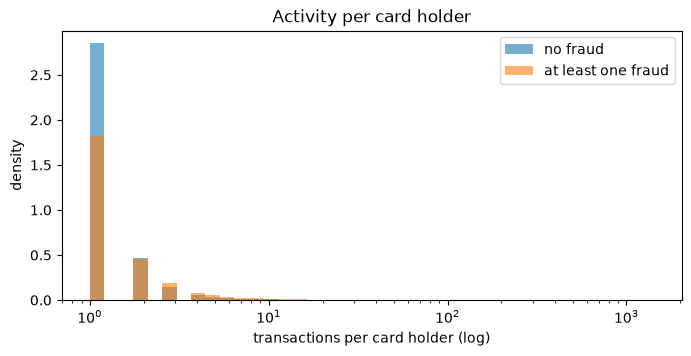

In [2]:
per_entity = df.groupby(ENTITY_COL, observed=True)[TARGET].agg(n="size", fraud="sum")
q = per_entity["n"].quantile([.5, .9, .99]).to_dict()
print(f"card holders: {len(per_entity):,}; transactions per card holder median {q[.5]:.0f}, p90 {q[.9]:.0f}, p99 {q[.99]:.0f}, max {per_entity['n'].max():,}")
print(f"card holders with a single transaction: {(per_entity['n'] == 1).mean():.1%}")
print(f"transactions from card holders with >= 10 transactions: {per_entity.loc[per_entity['n'] >= 10, 'n'].sum() / len(df):.1%}")
print(f"fraud rate per transaction: {y.mean():.2%}; card holders with at least one fraud: {(per_entity['fraud'] > 0).mean():.2%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.logspace(0, np.log10(per_entity["n"].max() + 1), 40)
ax.hist(per_entity.loc[per_entity["fraud"] == 0, "n"], bins=bins, alpha=.6, label="no fraud", density=True)
ax.hist(per_entity.loc[per_entity["fraud"] > 0, "n"], bins=bins, alpha=.6, label="at least one fraud", density=True)
ax.set(xscale="log", xlabel="transactions per card holder (log)", ylabel="density", title="Activity per card holder")
ax.legend()
save(fig, "txns_per_entity")

## B. Money (P2): where is the loss?

The decision problem is priced in dollars, so the question is not only *how often* fraud happens but *how much* it costs and where.

In [3]:
fraud_usd = amt[y == 1].sum()
n_months = (df[TIME_COL].max() - df[TIME_COL].min()) / (30.44 * 86_400)
print(f"approve-all baseline: ${fraud_usd:,.0f} of fraud in {n_months:.1f} months (${fraud_usd / n_months:,.0f}/month), "
      f"{fraud_usd / amt.sum():.2%} of all dollars; mean fraud ${amt[y == 1].mean():.0f} vs legit ${amt[y == 0].mean():.0f}")

curve = loss_concentration(amt, y)
for share in [.01, .05, .1, .2, .5]:
    print(f"largest {share:.0%} of frauds -> {np.interp(share, curve.share_of_fraud_txns, curve.share_of_fraud_usd):.1%} of fraud dollars")

bands = pd.cut(amt, [0, 25, 50, 100, 200, 500, 1000, np.inf], labels=["<25", "25-50", "50-100", "100-200", "200-500", "500-1k", ">1k"])
by_amount = rate_and_loss(df, bands)
by_amount.round(4)

approve-all baseline: $3,083,845 of fraud in 6.0 months ($515,784/month), 3.87% of all dollars; mean fraud $149 vs legit $135
largest 1% of frauds -> 10.7% of fraud dollars
largest 5% of frauds -> 30.8% of fraud dollars
largest 10% of frauds -> 45.1% of fraud dollars
largest 20% of frauds -> 62.9% of fraud dollars
largest 50% of frauds -> 87.7% of fraud dollars


,n,share,fraud,fraud_rate,ci_low,ci_high,fraud_usd,share_fraud_usd,fraud_usd_rate
TransactionAmt,,,,,,,,,
<25,50829,0.0861,3150,0.0620,0.0599,0.0641,5.003106e+04,0.0162,0.0558
25-50,153695,0.2603,4683,0.0305,0.0296,0.0313,1.783110e+05,0.0578,0.0299
50-100,164095,0.2779,4788,0.0292,0.0284,0.0300,3.553463e+05,0.1152,0.0301
100-200,128041,0.2168,3899,0.0305,0.0295,0.0314,5.586807e+05,0.1812,0.0329
200-500,71001,0.1202,3135,0.0442,0.0427,0.0457,1.003253e+06,0.3253,0.0478
500-1k,15612,0.0264,829,0.0531,0.0497,0.0567,6.372926e+05,0.2067,0.0599
>1k,7267,0.0123,179,0.0246,0.0213,0.0285,3.009304e+05,0.0976,0.0241


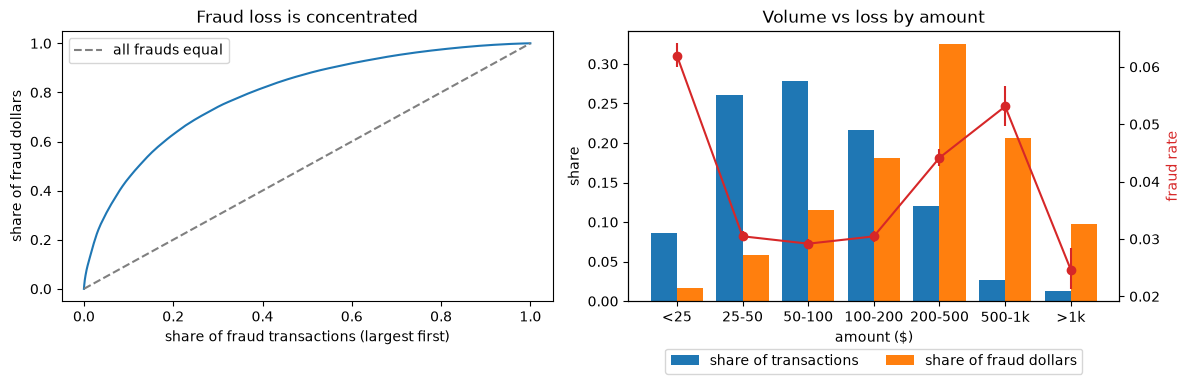

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(curve.share_of_fraud_txns, curve.share_of_fraud_usd)
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", label="all frauds equal")
axes[0].set(xlabel="share of fraud transactions (largest first)", ylabel="share of fraud dollars", title="Fraud loss is concentrated")
axes[0].legend()
x = np.arange(len(by_amount))
axes[1].bar(x - .2, by_amount["share"], .4, label="share of transactions")
axes[1].bar(x + .2, by_amount["share_fraud_usd"], .4, label="share of fraud dollars")
axes[1].set_xticks(x, by_amount.index)
axes[1].set(xlabel="amount ($)", ylabel="share", title="Volume vs loss by amount")
ax2 = axes[1].twinx()
ax2.errorbar(x, by_amount["fraud_rate"], yerr=errorbars(by_amount["fraud_rate"], by_amount["ci_low"], by_amount["ci_high"]), color="C3", marker="o", label="fraud rate")
ax2.set_ylabel("fraud rate", color="C3")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout()
save(fig, "loss_by_amount")

,n,share,fraud,fraud_rate,ci_low,ci_high,fraud_usd,share_fraud_usd,fraud_usd_rate
ProductCD,,,,,,,,,
W,439670,0.7445,8969,0.0204,0.0200,0.0208,2.054325e+06,0.6662,0.0305
C,68519,0.1160,8008,0.1169,0.1145,0.1193,3.914214e+05,0.1269,0.1332
R,37699,0.0638,1426,0.0378,0.0359,0.0398,3.480500e+05,0.1129,0.0549
H,33024,0.0559,1574,0.0477,0.0454,0.0500,2.466320e+05,0.0800,0.1021
S,11628,0.0197,686,0.0590,0.0549,0.0634,4.341600e+04,0.0141,0.0620


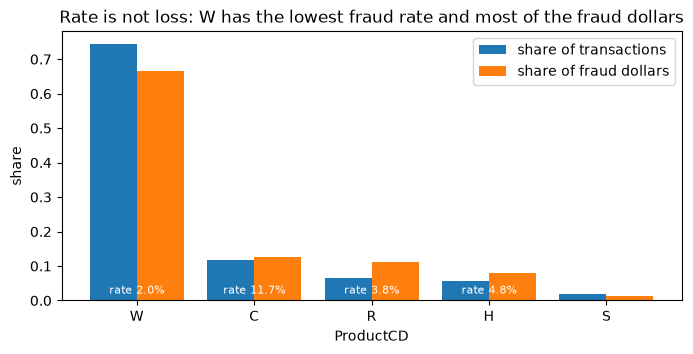

In [5]:
by_product = rate_and_loss(df, "ProductCD").sort_values("n", ascending=False)
display(by_product.round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(by_product))
for i, (col, label) in enumerate([("share", "share of transactions"), ("share_fraud_usd", "share of fraud dollars")]):
    ax.bar(x + (i - .5) * .4, by_product[col], .4, label=label)
ax.set_xticks(x, by_product.index)
ax.set(xlabel="ProductCD", ylabel="share", title="Rate is not loss: W has the lowest fraud rate and most of the fraud dollars")
for xi, rate in zip(x, by_product["fraud_rate"]):
    ax.annotate(f"rate {rate:.1%}", (xi, 0.02), ha="center", fontsize=8, color="white")
ax.legend()
save(fig, "product_rate_vs_loss")

In [6]:
# Amounts with 3 decimals look like currency conversions.
decimals = amount_decimals(amt)
display(rate_and_loss(df, decimals).round(4))
pd.crosstab(decimals, df["ProductCD"], normalize="index").round(2)

,n,share,fraud,fraud_rate,ci_low,ci_high,fraud_usd,share_fraud_usd,fraud_usd_rate
decimals,,,,,,,,,
0,305013,0.5165,10882,0.0357,0.0350,0.0363,2.327440e+06,0.7547,0.0560
1,22937,0.0388,430,0.0187,0.0171,0.0206,5.881780e+04,0.0191,0.0195
2,200657,0.3398,2092,0.0104,0.0100,0.0109,3.438162e+05,0.1115,0.0106
3,61933,0.1049,7259,0.1172,0.1147,0.1198,3.537709e+05,0.1147,0.1304


ProductCD,C,H,R,S,W
decimals,,,,,
0,0.00,0.11,0.12,0.04,0.73
1,0.02,0.00,0.00,0.00,0.98
2,0.03,0.00,0.00,0.00,0.97
3,1.00,0.00,0.00,0.00,0.00


## C. Signal (P1): which attributes separate fraud?

Mutual information (in nats) between each column and the label, on a 100k-row sample, against a label-permutation null (see `features.mi_table`). Used here to **describe** where information sits, not to select features.

In [7]:
mi = mi_table(df.sample(100_000, random_state=0), raw)
by_group = signal_by_group(mi)
display(by_group.round(5))
print("Top 15 single columns")
mi.head(15).round(5)

,n_cols,n_above_null,mi_median,mi_max,top_feature
group,,,,,
V1-V339,339,313,0.00494,0.01620,V258
DeviceInfo,1,1,0.01401,0.01401,DeviceInfo
C1-C14,14,13,0.00672,0.01204,C8
R_emaildomain,1,1,0.01129,0.01129,R_emaildomain
id_01-38,38,38,0.00753,0.01127,id_31
D1-D15,15,15,0.00725,0.01036,D8
ProductCD,1,1,0.01021,0.01021,ProductCD
addr1-2,2,2,0.00887,0.00895,addr2
card1-6,6,6,0.00253,0.00895,card3


Top 15 single columns


,mi,null_q,miller_madow_bias,n_bins,keep
feature,,,,,
V258,0.01620,0.00003,0.00002,4,True
V257,0.01596,0.00003,0.00002,4,True
V201,0.01595,0.00004,0.00002,4,True
V246,0.01578,0.00005,0.00002,4,True
V244,0.01564,0.00004,0.00002,4,True
V200,0.01557,0.00005,0.00002,4,True
V243,0.01546,0.00003,0.00002,4,True
V199,0.01545,0.00004,0.00002,4,True
V187,0.01529,0.00003,0.00002,4,True


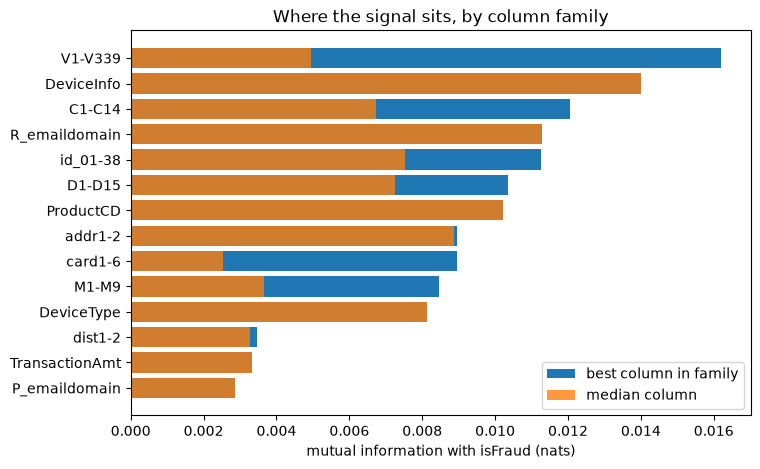

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
order = by_group.sort_values("mi_max")
ax.barh(order.index, order["mi_max"], label="best column in family")
ax.barh(order.index, order["mi_median"], label="median column", alpha=.8)
ax.set(xlabel="mutual information with isFraud (nats)", title="Where the signal sits, by column family")
ax.legend()
save(fig, "signal_by_group")

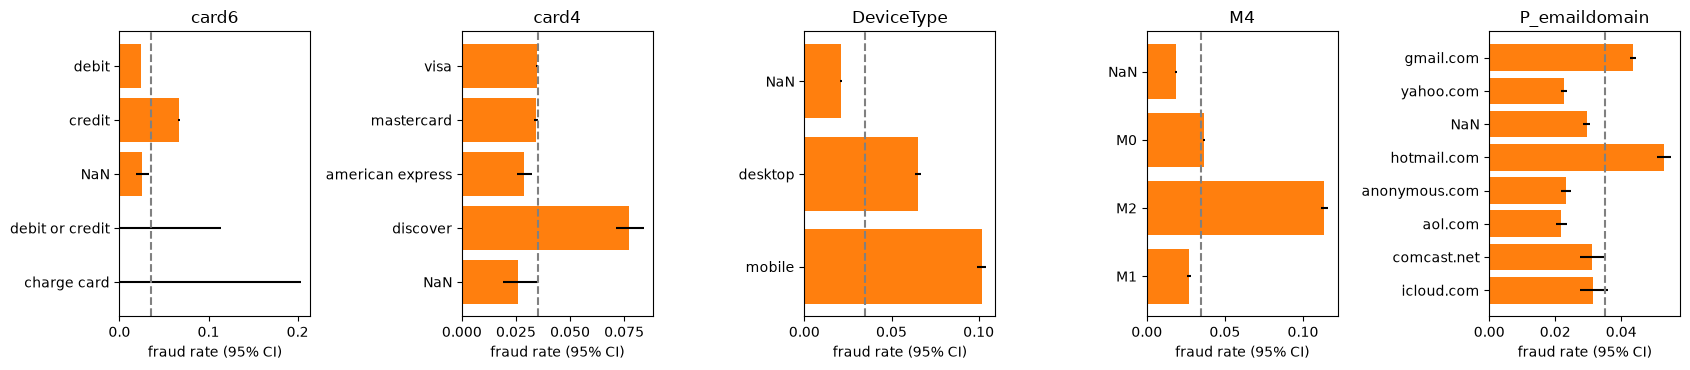

In [9]:
cats = ["card6", "card4", "DeviceType", "M4", "P_emaildomain"]
fig, axes = plt.subplots(1, len(cats), figsize=(17, 3.8))
for ax, col in zip(axes, cats):
    t = rate_and_loss(df, col).sort_values("n", ascending=False).head(8).iloc[::-1]
    ax.barh(t.index.astype(str), t["fraud_rate"], xerr=errorbars(t["fraud_rate"], t["ci_low"], t["ci_high"]), color="C1")
    ax.axvline(y.mean(), color="gray", ls="--")
    ax.set(title=col, xlabel="fraud rate (95% CI)")
fig.tight_layout()
save(fig, "categorical_rates")

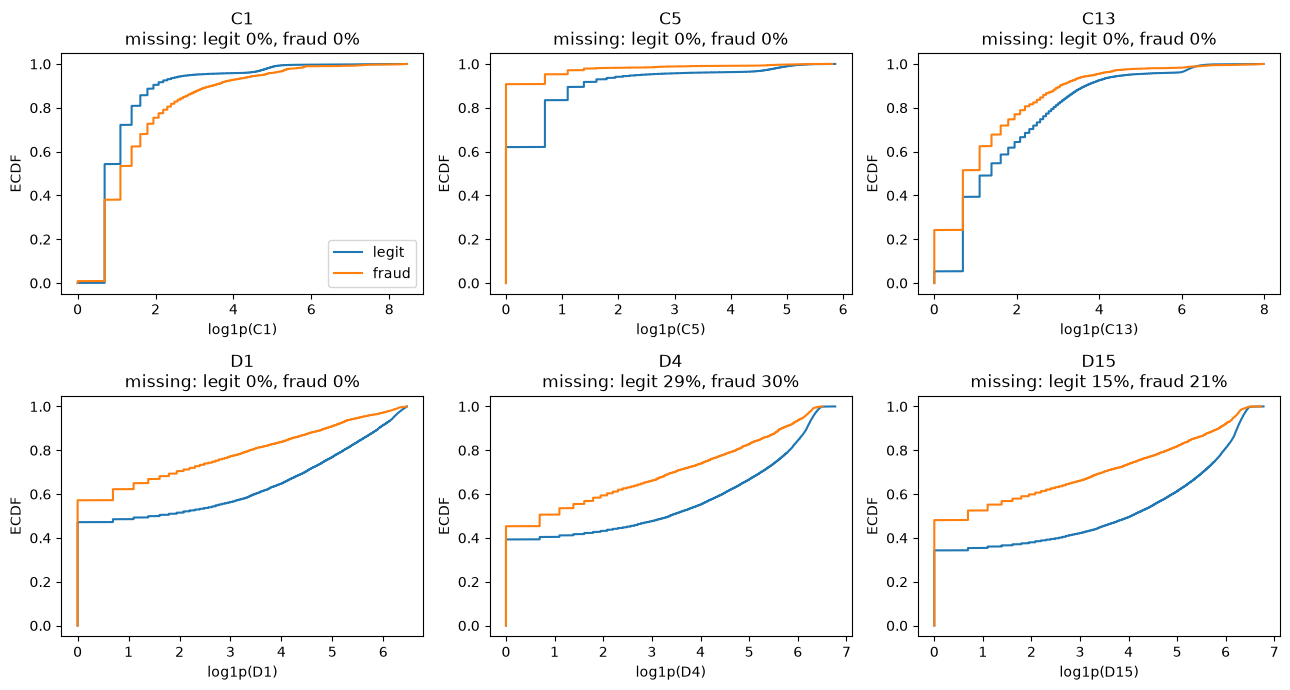

In [10]:
num_cols = ["C1", "C5", "C13", "D1", "D4", "D15"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.ravel()
for ax, col in zip(axes, num_cols):
    for label, mask in [("legit", y == 0), ("fraud", y == 1)]:
        v = np.sort(np.log1p(np.clip(df.loc[mask, col].dropna().astype(float), 0, None)))
        ax.plot(v, np.arange(1, len(v) + 1) / len(v), label=label)
    miss = df.groupby(y)[col].apply(lambda s: s.isna().mean())
    ax.set(title=f"{col}\nmissing: legit {miss[0]:.0%}, fraud {miss[1]:.0%}", xlabel=f"log1p({col})", ylabel="ECDF")
axes[0].legend()
fig.tight_layout()
save(fig, "numeric_by_class")

In [11]:
# Behind the ECDFs and the MI numbers: fraud rate by value band (95% CI).
from fraud.analysis import value_band as band

for name, key in [
    ("card age D1 (days)", band(df["D1"], [-np.inf, 0, 30, np.inf], ["0", "1-30", ">30"])),
    ("V258 (highest-MI column)", band(df["V258"], [-np.inf, 0.5, 1.5, 2.5, np.inf], ["0", "1", "2", ">=3"])),
    ("C1 (count)", band(df["C1"], [-1, 1, 3, 10, 100, np.inf], ["0-1", "2-3", "4-10", "11-100", ">100"])),
]:
    print(name)
    display(rate_and_loss(df, key)[["n", "share", "fraud_rate", "ci_low", "ci_high"]].round(4))

card age D1 (days)


,n,share,fraud_rate,ci_low,ci_high
D1,,,,,
0,280130,0.4744,0.0421,0.0413,0.0428
1-30,76244,0.1291,0.0629,0.0612,0.0646
>30,232897,0.3944,0.0173,0.0168,0.0179
NaN,1269,0.0021,0.0362,0.0273,0.0480


V258 (highest-MI column)


,n,share,fraud_rate,ci_low,ci_high
V258,,,,,
0,6,0.0000,0.1667,0.0301,0.5635
1,112953,0.1913,0.0397,0.0386,0.0409
2,11247,0.0190,0.1689,0.1621,0.1760
>=3,6224,0.0105,0.6117,0.5995,0.6237
NaN,460110,0.7791,0.0228,0.0223,0.0232


C1 (count)


,n,share,fraud_rate,ci_low,ci_high
C1,,,,,
0-1,317285,0.5373,0.0248,0.0242,0.0253
11-100,20586,0.0349,0.1295,0.1249,0.1341
2-3,156386,0.2648,0.0321,0.0313,0.0330
4-10,76185,0.1290,0.0528,0.0513,0.0544
>100,20098,0.0340,0.0545,0.0514,0.0577


volume lowest at hour 9, highest at 19; fraud rate 2.3% (hour 13) to 10.6% (hour 7)


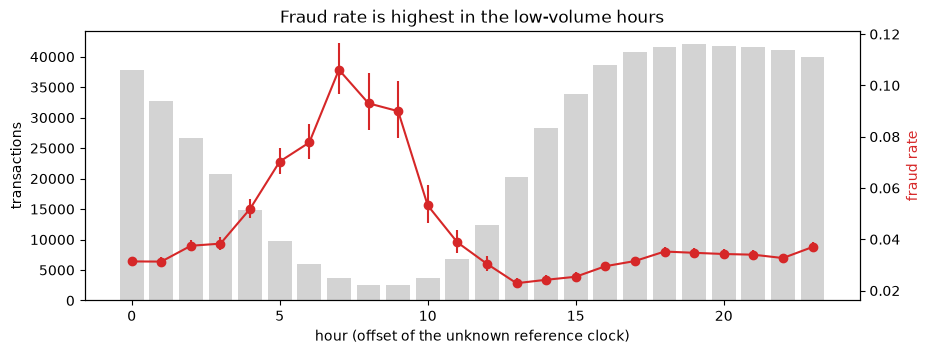

In [12]:
hour = ((df[TIME_COL] // 3600) % 24).rename("hour")
by_hour = rate_and_loss(df, hour)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(by_hour.index, by_hour["n"], color="lightgray")
ax.set(xlabel="hour (offset of the unknown reference clock)", ylabel="transactions")
ax2 = ax.twinx()
ax2.errorbar(by_hour.index, by_hour["fraud_rate"], yerr=errorbars(by_hour["fraud_rate"], by_hour["ci_low"], by_hour["ci_high"]), color="C3", marker="o")
ax2.set_ylabel("fraud rate", color="C3")
ax.set_title("Fraud rate is highest in the low-volume hours")
save(fig, "hour")
print(f"volume lowest at hour {by_hour['n'].idxmin()}, highest at {by_hour['n'].idxmax()}; "
      f"fraud rate {by_hour['fraud_rate'].min():.1%} (hour {by_hour['fraud_rate'].idxmin()}) to {by_hour['fraud_rate'].max():.1%} (hour {by_hour['fraud_rate'].idxmax()})")

In [13]:
# Interaction: does having device / network data mean the same thing in every product?
has_identity = np.where(df["id_01"].notna(), "identity", "no identity")
key = df["ProductCD"].astype(str) + " / " + has_identity
inter = rate_and_loss(df, key)
inter.index = pd.MultiIndex.from_tuples([tuple(i.split(" / ")) for i in inter.index], names=["ProductCD", "identity"])
inter[["n", "fraud_rate", "ci_low", "ci_high"]].round(4)

n  fraud_rate  ci_low  ci_high
ProductCD identity                                        
C         identity      62192      0.1228  0.1203   0.1254
          no identity    6327      0.0582  0.0527   0.0642
H         identity      32908      0.0477  0.0455   0.0501
          no identity     116      0.0259  0.0088   0.0733
R         identity      37548      0.0379  0.0360   0.0399
          no identity     151      0.0199  0.0068   0.0568
S         identity      11585      0.0590  0.0549   0.0635
          no identity      43      0.0465  0.0128   0.1546
W         no identity  439670      0.0204  0.0200   0.0208

C pairs with |r| > 0.9: 38 of 91


V: 339 columns in 14 blocks need 122 principal components for 95% of within-block variance


,n_cols,median_abs_corr,n_components
block,,,
V279-V321,32,0.240,9
V95-V137,43,0.117,15
V281-V315,11,0.273,7
V12-V34,23,0.099,9
V53-V74,22,0.254,10
V75-V94,20,0.191,10
V35-V52,18,0.278,9
V1-V11,11,0.306,6
V220-V272,16,0.296,7


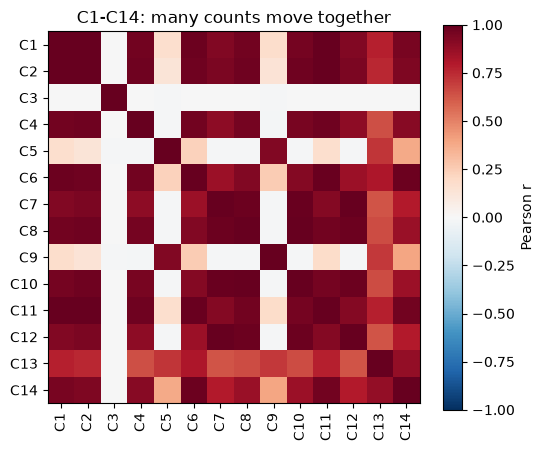

In [14]:
# How much independent information is there? Correlation inside families and blocks.
C = [f"C{i}" for i in range(1, 15)]
corr_c = df[C].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr_c, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(C)), C, rotation=90)
ax.set_yticks(range(len(C)), C)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("C1-C14: many counts move together")
save(fig, "c_correlation")
print(f"C pairs with |r| > 0.9: {int(((corr_c.abs() > .9).sum().sum() - len(C)) / 2)} of {len(C) * (len(C) - 1) // 2}")

V = [c for c in raw if column_group(c) == "V1-V339"]
blocks = missing_blocks(df, V)
redundancy = block_redundancy(df.sample(50_000, random_state=0), blocks)
print(f"V: {len(V)} columns in {len(blocks)} blocks need {redundancy['n_components'].sum()} principal components for 95% of within-block variance")
redundancy.round(3)

## D. Time (P3): what is stable and what changes?

Monitoring only makes sense if we know how much things move when nothing is wrong.

weekly fraud rate (full weeks): 1.85% to 5.06%; weekly fraud $ 86,721 to 167,635


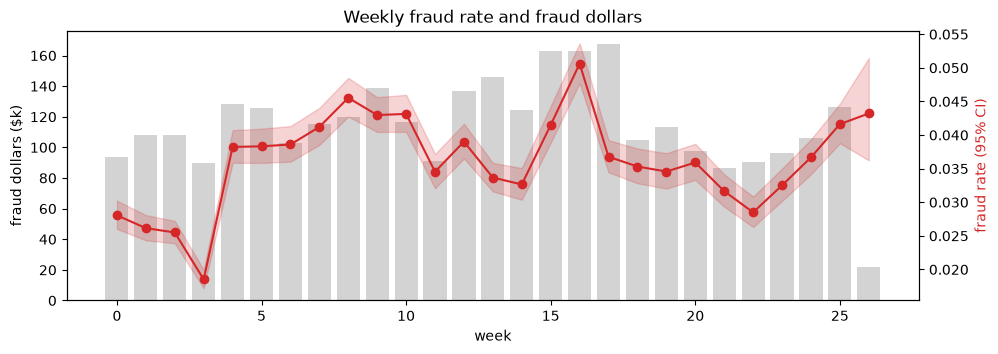

In [15]:
wk = weekly_profile(df)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(wk.index, wk["fraud_usd"] / 1e3, color="lightgray")
ax.set(xlabel="week", ylabel="fraud dollars ($k)")
ax2 = ax.twinx()
ax2.plot(wk.index, wk["fraud_rate"], color="C3", marker="o")
ax2.fill_between(wk.index, wk["ci_low"], wk["ci_high"], color="C3", alpha=.2)
ax2.set_ylabel("fraud rate (95% CI)", color="C3")
ax.set_title("Weekly fraud rate and fraud dollars")
save(fig, "weekly")
full = wk.iloc[:-1]  # last week is partial
print(f"weekly fraud rate (full weeks): {full['fraud_rate'].min():.2%} to {full['fraud_rate'].max():.2%}; weekly fraud $ {full['fraud_usd'].min():,.0f} to {full['fraud_usd'].max():,.0f}")

,W,C,R,H,S
month,,,,,
2017-12,0.019,0.082,0.010,0.018,0.026
2018-01,0.021,0.127,0.100,0.142,0.076
2018-02,0.021,0.125,0.091,0.127,0.104
2018-03,0.022,0.128,0.065,0.096,0.078
2018-04,0.021,0.124,0.045,0.059,0.063
2018-05,0.018,0.134,0.049,0.063,0.053
2018-06,0.021,0.179,0.095,0.092,0.125


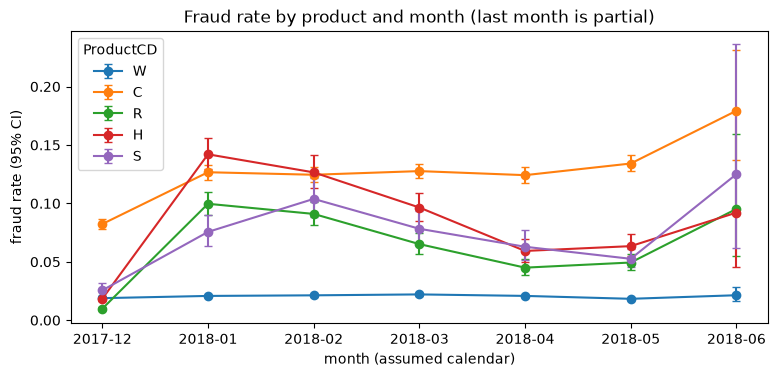

In [16]:
monthly = {p: rate_and_loss(df[df["ProductCD"] == p], "month") for p in by_product.index}
fig, ax = plt.subplots(figsize=(9, 3.8))
for p, t in monthly.items():
    ax.errorbar(t.index.astype(str), t["fraud_rate"], yerr=errorbars(t["fraud_rate"], t["ci_low"], t["ci_high"]), marker="o", capsize=3, label=p)
ax.set(xlabel="month (assumed calendar)", ylabel="fraud rate (95% CI)", title="Fraud rate by product and month (last month is partial)")
ax.legend(title="ProductCD")
save(fig, "product_by_month")
pd.DataFrame({p: t["fraud_rate"] for p, t in monthly.items()}).round(3)

week-to-week range of block missing rates (max - min):


V1-V11 (11)       0.510
V220-V272 (16)    0.424
V167-V216 (31)    0.413
V169-V210 (19)    0.413
V217-V278 (46)    0.404
V322-V339 (18)    0.391
V138-V166 (29)    0.391
V53-V74 (22)      0.373
V35-V52 (18)      0.360
V12-V34 (23)      0.357
V75-V94 (20)      0.348
V281-V315 (11)    0.018
V95-V137 (43)     0.008
V279-V321 (32)    0.000
dtype: float64

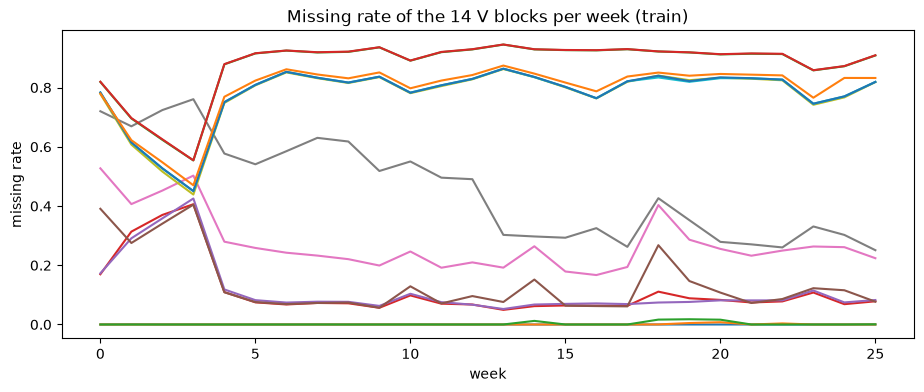

In [17]:
block_nulls = block_null_rate_by_week(df, blocks)
fig, ax = plt.subplots(figsize=(11, 4))
block_nulls.iloc[:-1].plot(ax=ax, legend=False)
ax.set(xlabel="week", ylabel="missing rate", title="Missing rate of the 14 V blocks per week (train)")
save(fig, "block_nulls_by_week")
spread = (block_nulls.iloc[:-1].max() - block_nulls.iloc[:-1].min()).sort_values(ascending=False)
print("week-to-week range of block missing rates (max - min):")
spread.round(3)

,id_31 (browser),id_30 (OS),DeviceInfo (device),P_emaildomain (email domain),card1 (card1)
mean,0.020,0.001,0.020,0.0,0.022
min,0.000,0.000,0.010,0.0,0.008
max,0.244,0.003,0.042,0.0,0.107


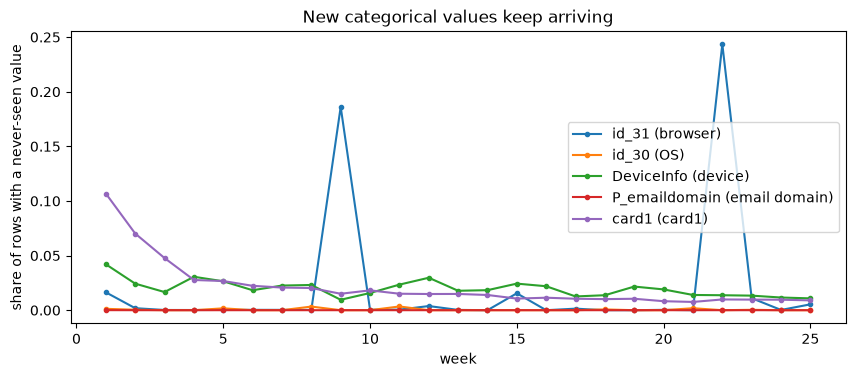

In [18]:
cols = {"id_31": "browser", "id_30": "OS", "DeviceInfo": "device", "P_emaildomain": "email domain", "card1": "card1"}
new_rates = pd.DataFrame({f"{c} ({name})": new_value_rate_by_week(df, c) for c, name in cols.items()})
fig, ax = plt.subplots(figsize=(10, 3.8))
new_rates.iloc[1:-1].plot(ax=ax, marker=".")
ax.set(xlabel="week", ylabel="share of rows with a never-seen value", title="New categorical values keep arriving")
save(fig, "new_values_by_week")
new_rates.iloc[1:-1].describe().loc[["mean", "min", "max"]].round(3)

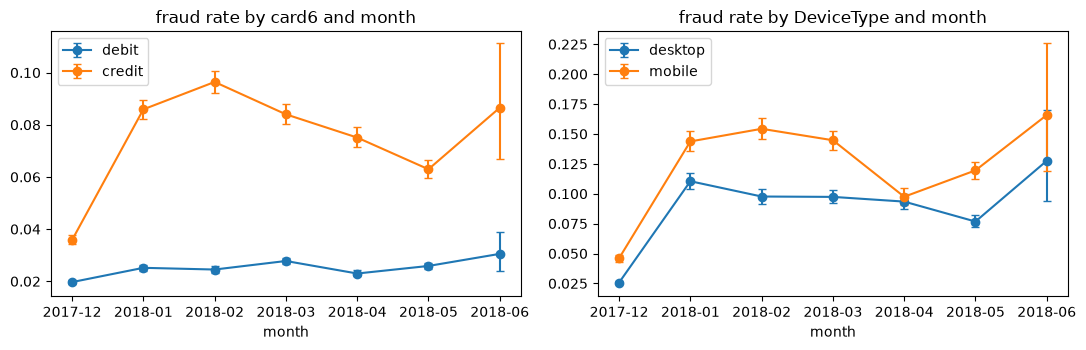

In [19]:
# Does the relation between an attribute and fraud stay the same over time?
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col in zip(axes, ["card6", "DeviceType"]):
    for value in df[col].dropna().astype(str).value_counts().head(2).index:
        t = rate_and_loss(df[df[col].astype(str) == value], "month")
        ax.errorbar(t.index.astype(str), t["fraud_rate"], yerr=errorbars(t["fraud_rate"], t["ci_low"], t["ci_high"]), marker="o", capsize=3, label=value)
    ax.set(title=f"fraud rate by {col} and month", xlabel="month")
    ax.legend()
fig.tight_layout()
save(fig, "relation_by_month")

## E. Labels (P4): how are they structured?

Labels are chargebacks propagated to later transactions of the same account, email or address.

card holders with fraud: 8,116; fraud transactions: 20,663
fraud transactions in card holders with more than one fraud: 78.0%
fraud streak (first to last fraud), days: median 0.0, p75 0.7, p90 13.1, max 181
fraud card holders with legitimate transactions before the first fraud: 25.5%
fraud card holders with legitimate transactions between frauds: 11.2%
fraud card holders with legitimate transactions after the last fraud: 24.3%


,first_fraud,repeat_fraud
week,,
0,0.0149,0.0131
1,0.0128,0.0134
2,0.0109,0.0146
3,0.0079,0.0106
10,0.0157,0.0275
20,0.0132,0.0227
25,0.0156,0.0260


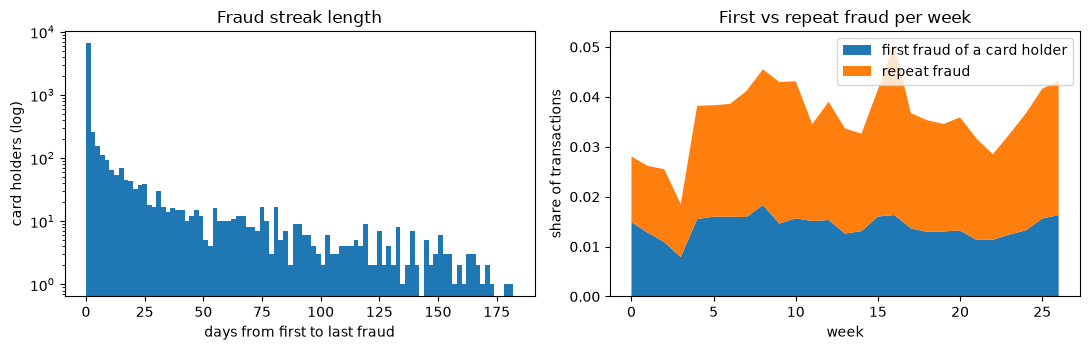

In [20]:
prof = entity_fraud_profile(df)
fraud_txns = prof["n_fraud"].sum()
print(f"card holders with fraud: {len(prof):,}; fraud transactions: {fraud_txns:,}")
print(f"fraud transactions in card holders with more than one fraud: {prof.loc[prof['n_fraud'] > 1, 'n_fraud'].sum() / fraud_txns:.1%}")
print(f"fraud streak (first to last fraud), days: median {prof['streak_days'].median():.1f}, p75 {prof['streak_days'].quantile(.75):.1f}, p90 {prof['streak_days'].quantile(.9):.1f}, max {prof['streak_days'].max():.0f}")
for col, label in [("n_legit_before", "before the first fraud"), ("n_legit_during", "between frauds"), ("n_legit_after", "after the last fraud")]:
    print(f"fraud card holders with legitimate transactions {label}: {(prof[col] > 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(prof["streak_days"], bins=np.arange(0, prof["streak_days"].max() + 2, 2))
axes[0].set(yscale="log", xlabel="days from first to last fraud", ylabel="card holders (log)", title="Fraud streak length")
kinds = fraud_kind_by_week(df)
axes[1].stackplot(kinds.index, kinds["first_fraud"], kinds["repeat_fraud"], labels=["first fraud of a card holder", "repeat fraud"])
axes[1].set(xlabel="week", ylabel="share of transactions", title="First vs repeat fraud per week")
axes[1].legend(loc="upper right")
fig.tight_layout()
save(fig, "entity_streaks")
kinds.iloc[[0, 1, 2, 3, 10, 20, 25]].round(4)

## F. Data quality

In [21]:
nc = near_constant(df, raw)
print(f"{len(nc)} columns have one value (NaN included) on >= 99% of rows:")
display(nc.round(4).to_frame().T)
neg = {c: int((df[c] < 0).sum()) for c in raw if df[c].dtype.kind == "f" and (df[c] < 0).any()}
print("columns with negative values (count):", neg)
dup = df.duplicated(subset=[c for c in raw]).sum()
print(f"rows identical to another on every input column (time and ID excluded): {dup:,}")

24 columns have one value (NaN included) on >= 99% of rows:


,V305,V107,V117,V119,V118,V120,V122,V111,V113,C3,V121,V108,V112,id_24,V110,id_25,id_08,id_07,id_21,id_26,id_23,id_22,id_27,V114
top_value_share,1.0,0.999,0.9982,0.9982,0.9978,0.9978,0.9971,0.9965,0.996,0.9959,0.995,0.9944,0.9944,0.992,0.9916,0.9913,0.9913,0.9913,0.9913,0.9913,0.9912,0.9912,0.9912,0.9901


columns with negative values (count): {'D4': 15, 'D6': 3, 'D11': 7, 'D12': 2, 'D14': 3, 'D15': 15, 'id_01': 124678, 'id_03': 187, 'id_04': 585, 'id_05': 6097, 'id_06': 45540, 'id_07': 347, 'id_08': 4894, 'id_09': 463, 'id_10': 2047, 'id_14': 79113}


rows identical to another on every input column (time and ID excluded): 487
